In [ ]:
!apt-get update
!apt-get install -y libopencv-dev build-essential cmake

Get:1 https://cli.github.com/packages stable InRelease [3,917 B]
Hit:2 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ InRelease
Hit:3 https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2404/x86_64  InRelease
Hit:4 http://archive.ubuntu.com/ubuntu noble InRelease
Hit:5 http://security.ubuntu.com/ubuntu noble-security InRelease
Hit:6 http://archive.ubuntu.com/ubuntu noble-updates InRelease
Hit:7 http://archive.ubuntu.com/ubuntu noble-backports InRelease
Hit:8 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu noble InRelease
Hit:9 https://r2u.stat.illinois.edu/ubuntu noble InRelease
Hit:10 https://ppa.launchpadcontent.net/graphics-drivers/ppa/ubuntu noble InRelease
Fetched 3,917 B in 1s (2,807 B/s)
Reading package lists... Done
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading package lists... Done
Building dependen

In [ ]:
%%writefile main.cpp
#include <iostream>
#include <opencv2/opencv.hpp>
#include <cuda_runtime.h>

int main() {
    std::cout << "OpenCV Versiyonu: " << CV_VERSION << std::endl;

    // Colab GPU Bağlantı Kontrolü
    int deviceCount = 0;
    cudaError_t error = cudaGetDeviceCount(&deviceCount);

    if (error == cudaSuccess && deviceCount > 0) {
        std::cout << "Başarılı! Colab GPU (CUDA) Algılandı. Cihaz Sayısı: " << deviceCount << std::endl;
    } else {
        std::cout << "CUDA Cihazı Bulunamadı veya GPU Aktif Edilmedi!" << std::endl;
    }

    return 0;
}

Overwriting main.cpp


In [ ]:
!g++ main.cpp -o app `pkg-config --cflags --libs opencv4` -I/usr/local/cuda/include -L/usr/local/cuda/lib64 -lcudart
!./app

OpenCV Versiyonu: 4.6.0
Başarılı! Colab GPU (CUDA) Algılandı. Cihaz Sayısı: 1


In [ ]:
%%writefile setup.sh
#!/bin/bash
echo "[1/3] Paket güncellemeleri ve OpenCV kurulumu yapılıyor..."
apt-get update -qq && apt-get install -y -qq libopencv-dev build-essential cmake > /dev/null

echo "[2/3] C++ uygulaması derleniyor..."
g++ main.cpp -o app `pkg-config --cflags --libs opencv4` -I/usr/local/cuda/include -L/usr/local/cuda/lib64 -lcudart

echo "[3/3] Uygulama çalıştırılıyor..."
./app

Overwriting setup.sh


In [ ]:
!bash setup.sh

[1/3] Paket güncellemeleri ve OpenCV kurulumu yapılıyor...
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
[2/3] C++ uygulaması derleniyor...
[3/3] Uygulama çalıştırılıyor...
OpenCV Versiyonu: 4.6.0
Başarılı! Colab GPU (CUDA) Algılandı. Cihaz Sayısı: 1


In [4]:

%%writefile frekans_filtresi.cpp
#include <iostream>
#include <vector>
#include <complex>
#include <cmath>
#include <random>
#include <fstream>
using namespace std;

const double PI = acos(-1.0);
const int N = 1000;
const double Fs = 1000.0;
const double esik = 2.0;

// DFT hesaplama
vector<complex<double>> DFT(const vector<double>& sinyal) {
    vector<complex<double>> X(N);

    for (int k = 0; k < N; k++) {
        X[k] = 0;

        for (int n = 0; n < N; n++) {
            double aci = -2 * PI * k * n / N;
            X[k] += sinyal[n] *
                    complex<double>(cos(aci), sin(aci));
        }
    }
    return X;
}

// Harmonik genliklerini hesaplama
vector<double> genlikHesapla(
    const vector<complex<double>>& X) {

    vector<double> genlik(N / 2 + 1);

    for (int k = 0; k <= N / 2; k++) {
        genlik[k] = 2.0 * abs(X[k]) / N;

        if (k == 0 || k == N / 2)
            genlik[k] /= 2.0;
    }
    return genlik;
}

// Esik degerinin altindaki harmonikleri filtrele
vector<complex<double>> filtrele(
    vector<complex<double>> X) {

    vector<double> genlik = genlikHesapla(X);

    for (int k = 0; k <= N / 2; k++) {
        if (genlik[k] < esik) {
            X[k] = 0;

            // Negatif frekans eslenigini de sifirla
            if (k > 0 && k < N / 2)
                X[N - k] = 0;
        }
    }
    return X;
}

// Ters DFT ile sinyali yeniden olustur
vector<double> IDFT(
    const vector<complex<double>>& X) {

    vector<double> sonuc(N);

    for (int n = 0; n < N; n++) {
        complex<double> toplam(0, 0);

        for (int k = 0; k < N; k++) {
            double aci = 2 * PI * k * n / N;
            toplam += X[k] *
                      complex<double>(cos(aci), sin(aci));
        }

        sonuc[n] = toplam.real() / N;
    }
    return sonuc;
}

// Verileri CSV dosyasina kaydet
void kaydet(string dosya,
            const vector<double>& x,
            const vector<double>& y) {

    ofstream cikti(dosya);
    cikti << "x,y\n";

    for (int i = 0; i < (int)x.size(); i++) {
        cikti << x[i] << "," << y[i] << "\n";
    }
}

int main() {
    vector<double> zaman(N);
    vector<double> s1(N), s2(N), toplam(N);

    mt19937 uretici(42);
    normal_distribution<double> gurultu(0.0, 1.0);

    // 5. odevdeki sinyalleri olustur
    for (int n = 0; n < N; n++) {
        zaman[n] = n / Fs;

        s1[n] = 12 * sin(2 * PI * 50 * zaman[n])
                + gurultu(uretici);

        s2[n] = 5 * sin(2 * PI * 30 * zaman[n])
                + gurultu(uretici);

        toplam[n] = s1[n] + s2[n];
    }

    // DFT analizleri
    auto X1 = DFT(s1);
    auto X2 = DFT(s2);
    auto XT = DFT(toplam);

    // Filtreleme
    auto F1 = filtrele(X1);
    auto F2 = filtrele(X2);
    auto FT = filtrele(XT);

    // IDFT ile yeniden olusturma
    auto temiz1 = IDFT(F1);
    auto temiz2 = IDFT(F2);
    auto temizT = IDFT(FT);

    // Frekans ekseni
    vector<double> frekans(N / 2 + 1);
    for (int k = 0; k <= N / 2; k++)
        frekans[k] = k * Fs / N;

    // Sinyalleri kaydet
    kaydet("s1.csv", zaman, s1);
    kaydet("s2.csv", zaman, s2);
    kaydet("toplam.csv", zaman, toplam);

    kaydet("temiz1.csv", zaman, temiz1);
    kaydet("temiz2.csv", zaman, temiz2);
    kaydet("temizToplam.csv", zaman, temizT);

    // Harmonik vektorlerini kaydet
    kaydet("dft1.csv", frekans, genlikHesapla(X1));
    kaydet("dft2.csv", frekans, genlikHesapla(X2));
    kaydet("dftToplam.csv", frekans, genlikHesapla(XT));

    kaydet("filtre1.csv", frekans, genlikHesapla(F1));
    kaydet("filtre2.csv", frekans, genlikHesapla(F2));
    kaydet("filtreToplam.csv", frekans, genlikHesapla(FT));

    cout << "Frekans filtresi tamamlandi!" << endl;
    cout << "Esik degeri: " << esik << endl;
    cout << "3 sinyal filtrelendi ve yeniden olusturuldu."
         << endl;

    return 0;
}


Writing frekans_filtresi.cpp


In [5]:

!g++ -std=c++17 -O2 frekans_filtresi.cpp -o frekans_filtresi
!./frekans_filtresi


Frekans filtresi tamamlandi!
Esik degeri: 2
3 sinyal filtrelendi ve yeniden olusturuldu.


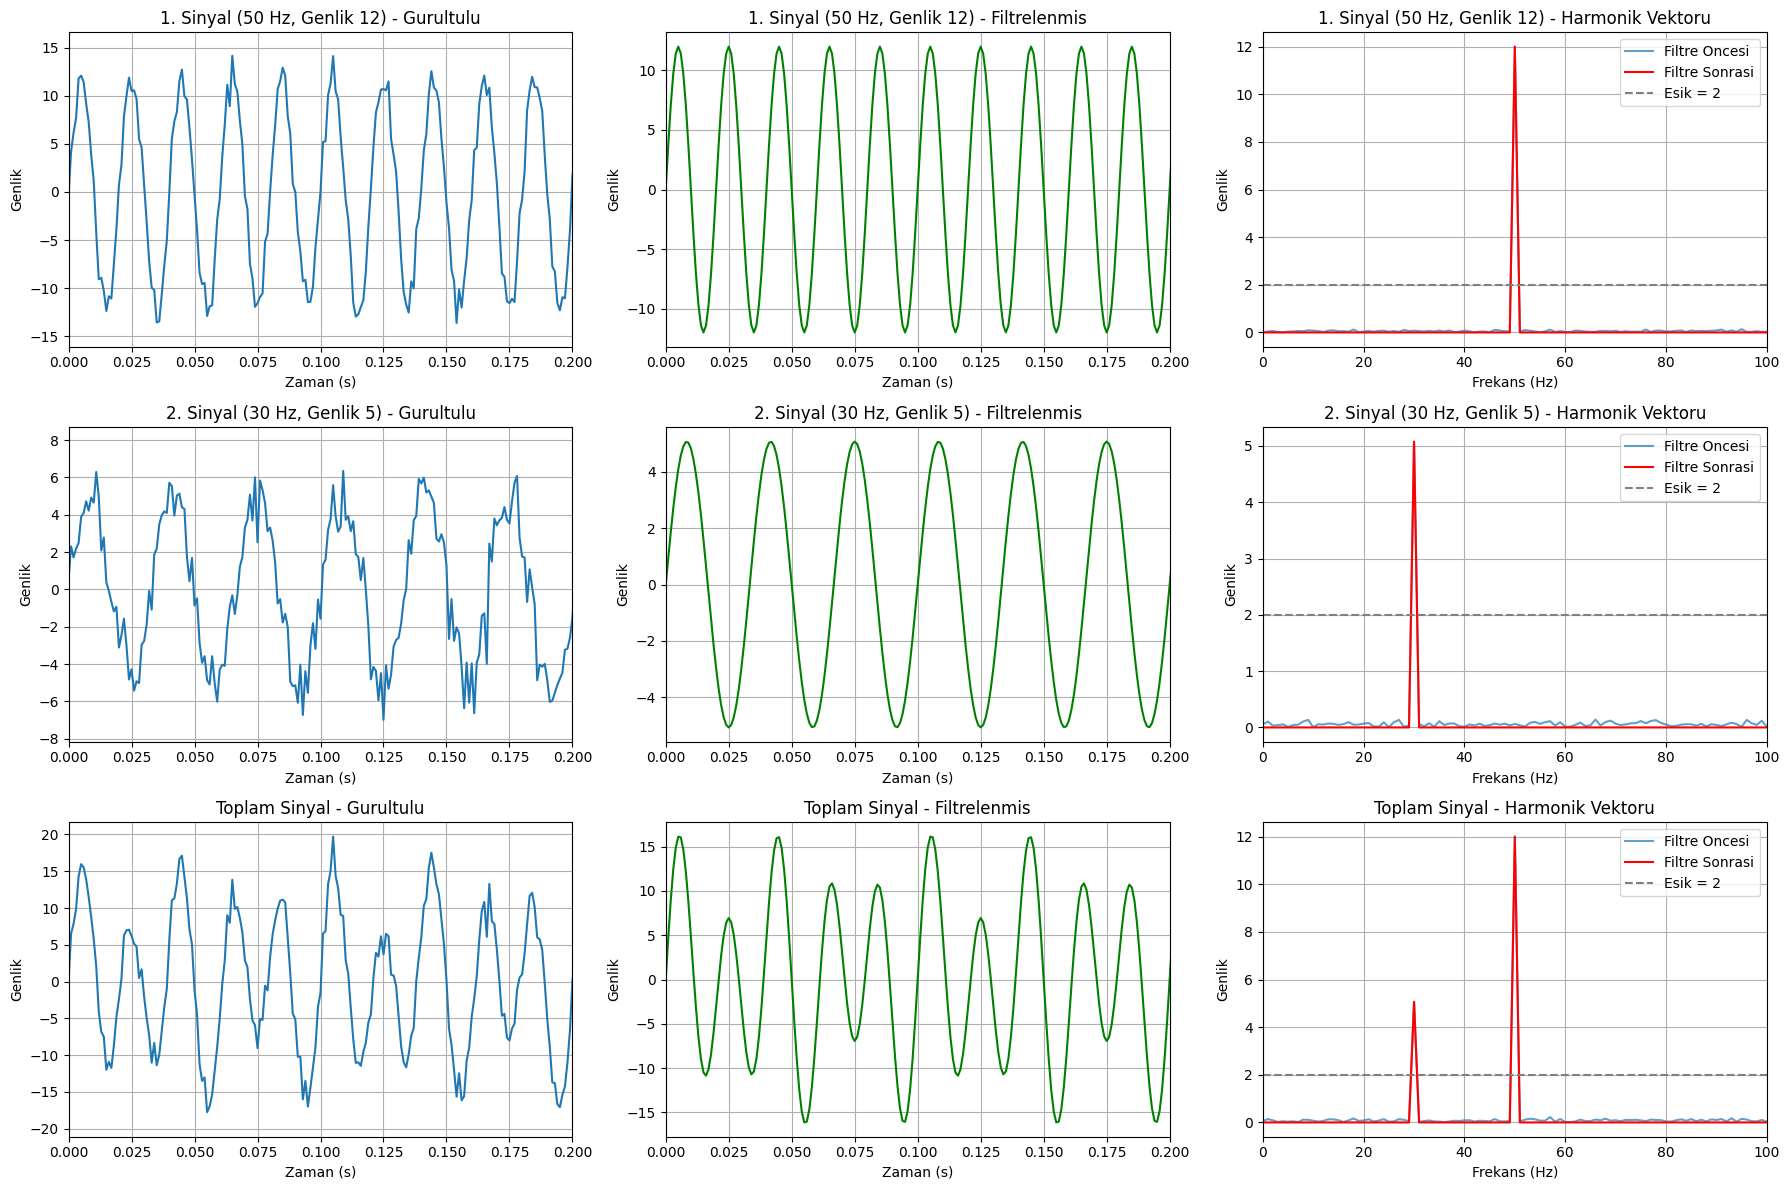

In [6]:

import pandas as pd
import matplotlib.pyplot as plt

# CSV dosyalarini oku
sinyaller = [
    ("s1.csv", "temiz1.csv", "dft1.csv", "filtre1.csv",
     "1. Sinyal (50 Hz, Genlik 12)"),

    ("s2.csv", "temiz2.csv", "dft2.csv", "filtre2.csv",
     "2. Sinyal (30 Hz, Genlik 5)"),

    ("toplam.csv", "temizToplam.csv",
     "dftToplam.csv", "filtreToplam.csv",
     "Toplam Sinyal")
]

fig, ax = plt.subplots(3, 3, figsize=(18, 12))

for i, (ham, temiz, dft, filtre, baslik) in enumerate(sinyaller):

    s = pd.read_csv(ham)
    t = pd.read_csv(temiz)
    d = pd.read_csv(dft)
    f = pd.read_csv(filtre)

    # Orijinal gurultulu sinyal
    ax[i, 0].plot(s["x"], s["y"])
    ax[i, 0].set_title(baslik + " - Gurultulu")
    ax[i, 0].set_xlabel("Zaman (s)")
    ax[i, 0].set_ylabel("Genlik")
    ax[i, 0].set_xlim(0, 0.2)

    # Filtrelenmis sinyal
    ax[i, 1].plot(t["x"], t["y"], color="green")
    ax[i, 1].set_title(baslik + " - Filtrelenmis")
    ax[i, 1].set_xlabel("Zaman (s)")
    ax[i, 1].set_ylabel("Genlik")
    ax[i, 1].set_xlim(0, 0.2)

    # DFT karsilastirmasi
    ax[i, 2].plot(d["x"], d["y"],
                  label="Filtre Oncesi", alpha=0.7)
    ax[i, 2].plot(f["x"], f["y"],
                  label="Filtre Sonrasi", color="red")
    ax[i, 2].axhline(2, color="gray",
                     linestyle="--", label="Esik = 2")

    ax[i, 2].set_title(baslik + " - Harmonik Vektoru")
    ax[i, 2].set_xlabel("Frekans (Hz)")
    ax[i, 2].set_ylabel("Genlik")
    ax[i, 2].set_xlim(0, 100)
    ax[i, 2].legend()

for a in ax.flat:
    a.grid(True)

plt.tight_layout()
plt.savefig("frekans_filtresi_sonuclari.png", dpi=200)
plt.show()
